# Aula 02 - Explicabilidade Global com SHAP e a Teoria dos Jogos Cooperativos

**Disciplina:** Inteligência Artificial Explicável (XAI) & Otimização de Modelos  
**Autor / Pesquisador:** Eduardo Lázaro Roesler de Oliveira  
**Instituição:** UNESP — Universidade Estadual Paulista "Júlio de Mesquita Filho" (Mestrado)  

> **Escopo:** Todos os dados sao sinteticos. Os nomes de saude usados em alguns exemplos sao ilustrativos e nao representam pacientes ou biomarcadores reais.

> 🔙 **De onde viemos:** Na Aula 01, construímos um classificador Baseline com Random Forest sobre 40 atributos sintéticos. A análise SHAP permite examinar como o modelo usa essas variáveis, sem identificar biomarcadores reais ou relações causais.
> 🎯 **Objetivo Principal da Aula:** Dominar os fundamentos da Teoria dos Jogos Cooperativos de Lloyd Shapley aplicados à Inteligência Artificial (**SHAP — SHapley Additive exPlanations**), implementar o algoritmo otimizado **TreeSHAP** (`shap.TreeExplainer`), computar o ranking de importância média global ($|\text{SHAP}|$) e interpretar gráficos de impacto direcional (**Beeswarm Plot**).
> 🚀 **Para onde vamos:** Na Aula 03, usaremos o **LIME** para auditar localmente uma observação sintética cuja probabilidade predita esteja próxima de 50%; isso não constitui uma decisão médica.

## Organização Tática da Aula

| Módulo | Atividade | Foco Pedagógico |
| :--- | :--- | :--- |
| **Módulo 1** | **Fundamentação Teórica & Teoria dos Jogos** | A intuição matemática dos Valores Shapley e como a distribuição de mérito em jogos cooperativos resolve a explicabilidade de IA. |
| **Módulo 2** | **O Mecanismo por Dentro & TreeSHAP vs. Abordagens Clássicas** | Por que a importância Gini do Random Forest é tendenciosa e como o TreeSHAP reduz complexidade exponencial para polinomial. |
| **Módulo 3** | **Prática Guiada no Google Colab** | 5 blocos de código em Python minuciosamente comentados linha por linha, com caixas de dúvidas e gráficos Beeswarm. |
| **Módulo 4** | **Prática Orientada & Experimentação Fácil** | Experimentação com amostragem e análise do impacto da variação de parâmetros visuais. |
| **Módulo 5** | **Checklist de Autonomia & Bibliografia** | Autoavaliação do estudante e referências seminais de XAI. |

## Módulo 1: Fundamentação Teórica & Teoria dos Jogos de Lloyd Shapley

### 1.1 A Pergunta Central da Explicabilidade Global
Em um modelo de aprendizado de máquina, quando ele prevê que um paciente tem **88% de probabilidade de patologia**, nós temos uma pergunta ética e científica inegociável:
> *"Quanto desse prognóstico foi responsabilidade de cada exame realizado?"*

Em **1953, o matemático Lloyd Shapley** propôs uma solução para um problema análogo na teoria dos jogos cooperativos: se um grupo de jogadores forma uma coalizão para produzir um valor conjunto (lucro ou vitória), como dividir a recompensa de maneira que nenhum participante seja injustiçado?

Em **2017, Scott Lundberg e Su-In Lee** demonstraram que podemos enxergar um modelo de IA exatamente como um jogo cooperativo:
- **Os Jogadores:** São os atributos de entrada (biomarcadores, exames, ruídos).
- **O Jogo:** É a função preditiva do modelo ($f(x)$).
- **A Recompensa:** É a predição final (a probabilidade ou score gerado).
- **O Valor Shapley ($\phi_i$):** É a contribuição marginal justa que o atributo $i$ teve para afastar a previsão do valor médio esperado da população!

```mermaid
graph TD
    A["🎲 Previsão Média da População (Base Value: 40%)"] --> B["🧪 Biomarcador 1 (+25%)<br/>Empurra para Patologia"]
    A --> C["🧪 Biomarcador 2 (+18%)<br/>Empurra para Patologia"]
    A --> D["📋 Exame Redundante 1 (-5%)<br/>Puxa para Saudável"]
    A --> E["🌪️ Ruído Metabólico (+0.01%)<br/>Impacto Praticamente Nulo"]
    B --> F["🏁 Previsão Final do Paciente: 78% Patologia"]
    C --> F
    D --> F
    E --> F
```

> ⚔️ **Analogia Geek — O Bônus de Missão dos Vingadores:**
> Imagine que a equipe dos Vingadores venceu um supervilão e recebeu uma recompensa de 1 milhão de moedas de ouro. O Homem de Ferro causou 40% do dano, Thor destruiu as naves, o Doutor Estranho abriu os portais de fuga e o Gavião Arqueiro atirou 3 flechas. Como dividir o ouro? Se dividirmos igualmente em 4 partes (como faz a média simples), Thor e Stark serão injustiçados! O Valor Shapley calcula quanto o time teria conquistado em **todas as combinações possíveis de heróis** (com e sem o Stark, com e sem o Gavião) para atribuir a fatia exata que cada herói gerou!

> 💡 **Curiosidade da Aula — O Nobel de Economia e o NeurIPS 2017:**
> Lloyd Shapley recebeu o **Prêmio Nobel de Economia em 2012** pela Teoria dos Jogos Estáveis. Apenas 5 anos depois, o pesquisador Scott Lundberg apresentou no prestigiado congresso **NeurIPS 2017** o artigo *"A Unified Approach to Interpreting Model Predictions"*, transformando os Valores Shapley no padrão-ouro da moderna indústria de IA (adotado por Google, Microsoft, Netflix e centros de medicina diagnóstica).

> 💡 **Em 1 Frase:** O SHAP calcula a contribuição de cada atributo medindo o quanto a previsão do modelo se altera quando aquele atributo está presente contra todas as combinações onde ele esteve ausente.

## Módulo 2: O Mecanismo por Dentro & Regras Práticas

### 2.1 A Equação dos Valores Shapley Desmistificada

A equação clássica de Shapley é dada por:

$$\phi_i(v) = \sum_{S \subseteq F \setminus \{i\}} \frac{|S|!(|F| - |S| - 1)!}{|F|!} \Big[ v(S \cup \{i\}) - v(S) \Big]$$

Vamos traduzir os símbolos matemáticos para linguagem humana:
- $F$: É o conjunto completo de todos os atributos disponíveis (no nosso caso, as 40 variáveis).
- $S$: É um subconjunto ("coalizão") de atributos sem o atributo $i$.
- $v(S \cup \{i\}) - v(S)$: É a **contribuição marginal** que o atributo $i$ trouxe ao entrar no grupo $S$.
- $\frac{|S|!(|F| - |S| - 1)!}{|F|!}$: É o peso combinatório (fatorial) que garante que todas as ordens de entrada na sala de votação tenham a mesma probabilidade.

### 2.2 Comparativo: Importância Clássica (Gini) vs. TreeSHAP

| Critério | Importância Nativa Random Forest (Gini / MDI) | Valores SHAP (TreeSHAP) |
| :--- | :--- | :--- |
| **Consistência Teórica** | **Baixa:** Pode atribuir alto valor a variáveis contínuas aleatórias (viés de cardinalidade). | **Alta:** Garantida por 4 axiomas matemáticos da teoria dos jogos (Eficiência, Simetria, Dummy e Aditividade). |
| **Direção do Efeito** | Não informa se a variável ajuda ou atrapalha a previsão (apenas um número positivo). | Informa magnitude E direção (valores positivos empurram para classe 1; negativos para classe 0). |
| **Complexidade Computacional** | Imediata ($O(1)$ pós-treino). | $O(T \cdot L \cdot D^2)$ (otimização polinomial veloz para árvores). |
| **Explicação Local** | Não fornece (mede apenas o comportamento global da floresta). | Fornece valores Shapley individuais para cada paciente e média global. |

> 💡 **Em 1 Frase:** Nunca tome decisões de descarte de atributos baseando-se apenas na importância Gini do Random Forest; use sempre o $|SHAP|$, que é rigorosamente imune a distorções estatísticas.

## Módulo 3: Prática Guiada no Google Colab

Abra o seu Notebook no [Google Colab](https://colab.research.google.com) e execute as células na ordem abaixo.

> **Roteiro de estudo:** Nós recuperaremos os dados e o modelo treinados na Aula 01. Em seguida, instanciaremos o `TreeExplainer` e geraremos dois gráficos espetaculares: o **Bar Plot de Importância Média** (colorido por tipo semântico de variável) e o **Beeswarm Summary Plot**.

### Bloco 2.1 — Preparação dos Dados e Reutilização do Baseline

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que recriamos a função `gerar_dataset_sintetico_saude()` aqui?**  
> Para garantir que este notebook seja totalmente autocontido e independente no Google Colab! Usando a mesma semente (`random_state=42`), garantimos exatamente os mesmos 40 atributos e dados da aula anterior.

In [1]:
# 1. Importamos as bibliotecas necessarias para computacao, graficos e XAI
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# 2. Definimos a funcao geradora de dados clinicos sinteticos identica a Aula 01
def gerar_dataset_sintetico_saude(n_samples=2000, n_features=40, n_informative=10, n_redundant=10, random_state=42):
    X_raw, y = make_classification(
        n_samples=n_samples,
        n_features=n_features,
        n_informative=n_informative,
        n_redundant=n_redundant,
        n_repeated=0,
        n_classes=2,
        weights=[0.6, 0.4],
        flip_y=0.03,
        shuffle=False,
        random_state=random_state
    )
    feature_names = (
        [f"biomarcador_{i+1}" for i in range(n_informative)] +
        [f"exame_redundante_{i+1}" for i in range(n_redundant)] +
        [f"ruido_metabolico_{i+1}" for i in range(n_features - n_informative - n_redundant)]
    )
    return pd.DataFrame(X_raw, columns=feature_names), y

# 3. Geramos o dataset e particionamos em treino e teste com estratificacao
X, y = gerar_dataset_sintetico_saude()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# 4. Ajustamos a floresta aleatoria de referencia (Baseline)
modelo_baseline = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1)
modelo_baseline.fit(X_train, y_train)

# 5. Exibimos a confirmacao de prontidao do modelo para explicabilidade
print(f"[OK] Modelo Baseline ajustado com sucesso sobre {X_train.shape[1]} atributos!")

c:\Users\eduar\projetos\xai_data_reduction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[OK] Modelo Baseline ajustado com sucesso sobre 40 atributos!


---

### Bloco 2.2 — Instanciando o `TreeExplainer` e Extraindo a Matriz SHAP

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que é o `TreeExplainer` e por que ele é muito mais rápido que o `KernelExplainer`?**  
> O `KernelExplainer` é agnóstico a modelos e precisa avaliar milhares de permutações combinatórias (tempo exponencial). Já o `TreeExplainer` aproveita a estrutura interna de nós e ramificações das árvores do Random Forest, calculando os valores Shapley exatos em tempo polinomial ultrarrápido!

In [2]:
# 1. Definimos a funcao que executa o calculo matematico do TreeSHAP
def calcular_explicacoes_shap(modelo, X_train):
    """
    Calcula os valores SHAP usando o algoritmo otimizado TreeExplainer.
    """
    # 2. Instanciamos o explicador de arvores passando nosso Random Forest treinado
    explainer = shap.TreeExplainer(modelo)
    
    # 3. Extraímos os valores SHAP calculados para todos os pacientes do conjunto de treino
    shap_values = explainer(X_train)
    
    # 4. Verificamos a dimensionalidade dos valores SHAP (formato 3D para classificacao binaria)
    if len(shap_values.shape) == 3:
        # 5. Extraímos exclusivamente a matriz de impacto da classe 1 (presenca de patologia)
        shap_vals_class1 = shap_values.values[:, :, 1]
    else:
        # 6. Para formatos 2D, extraímos diretamente os valores
        shap_vals_class1 = shap_values.values
        
    # 7. Computamos o modulo medio absoluto |SHAP| de cada coluna ao longo de todos os pacientes
    mean_abs_shap = np.abs(shap_vals_class1).mean(axis=0)
    
    # 8. Criamos uma tabela consolidando os nomes dos atributos e sua respectiva importancia media
    df_importancia = pd.DataFrame({
        "atributo": X_train.columns,
        "importancia_shap": mean_abs_shap
    }).sort_values(by="importancia_shap", ascending=False).reset_index(drop=True)
    
    # 9. Retornamos o objeto explicador, a matriz de valores e o DataFrame ordenado
    return explainer, shap_values, shap_vals_class1, df_importancia

# 10. Computamos a explicabilidade global com TreeSHAP
print("[*] Computando valores TreeSHAP no conjunto de treinamento... Aguarde alguns segundos...")
explainer, shap_values, shap_vals_class1, df_importancia = calcular_explicacoes_shap(modelo_baseline, X_train)

# 11. Exibimos os 10 atributos de maior impacto no console
print("\n" + "=" * 65)
print("--- TOP 10 ATRIBUTOS MAIS IMPORTANTES SEGUNDO O SHAP ---")
print("=" * 65)
for i, row in df_importancia.head(10).iterrows():
    print(f" {i+1:2d}. {row['atributo']:<25} | Importância Média |SHAP|: {row['importancia_shap']:.4f}")
print("=" * 65)

[*] Computando valores TreeSHAP no conjunto de treinamento... Aguarde alguns segundos...

--- TOP 10 ATRIBUTOS MAIS IMPORTANTES SEGUNDO O SHAP ---
  1. biomarcador_4             | Importância Média |SHAP|: 0.0783
  2. exame_redundante_5        | Importância Média |SHAP|: 0.0507
  3. exame_redundante_4        | Importância Média |SHAP|: 0.0488
  4. biomarcador_2             | Importância Média |SHAP|: 0.0395
  5. biomarcador_1             | Importância Média |SHAP|: 0.0284
  6. biomarcador_3             | Importância Média |SHAP|: 0.0248
  7. exame_redundante_9        | Importância Média |SHAP|: 0.0240
  8. biomarcador_8             | Importância Média |SHAP|: 0.0233
  9. biomarcador_10            | Importância Média |SHAP|: 0.0225
 10. biomarcador_9             | Importância Média |SHAP|: 0.0208


---

### Bloco 2.3 — Gráficos de Alto Impacto: Bar Plot Semântico e Beeswarm Plot

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Como interpretar os pontos vermelhos e azuis no Beeswarm Plot?**  
> Cada ponto representa uma observacao sintetica. A cor indica o valor da variavel (vermelho = alto; azul = baixo); o eixo horizontal mostra a contribuicao SHAP para a classe positiva ou negativa do modelo. Isso descreve o modelo neste benchmark, nao risco de doenca.

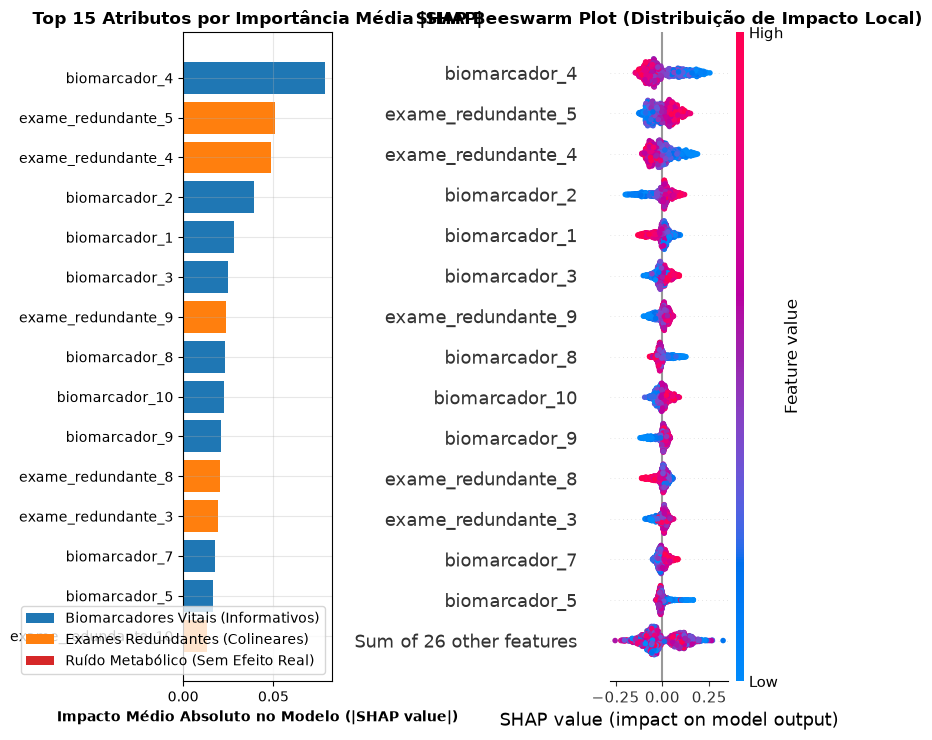

[+] Gráficos SHAP gerados e salvos com sucesso em: modulo2_shap_summary.png


In [3]:
# 1. Definimos a funcao de geracao dos paineis graficos de explicabilidade global
def gerar_graficos_shap(shap_values, X_train, df_importancia, output_path="modulo2_shap_summary.png"):
    """
    Plota o Bar Plot de relevância global e o Beeswarm Summary Plot lado a lado.
    """
    # 2. Criamos a figura contendo 1 linha e 2 colunas amplas
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    
    # 3. Extraímos o ranking dos 15 principais atributos
    top15 = df_importancia.head(15)
    
    # 4. Mapeamos cores semanticas: Azul para biomarcadores, Laranja para redundantes e Vermelho para ruidos
    colors = [
        '#1f77b4' if 'biomarcador' in name else ('#ff7f0e' if 'redundante' in name else '#d62728')
        for name in top15['atributo']
    ]
    
    # 5. Plotamos o grafico horizontal de barras invertendo a ordem para o maior ficar no topo
    axes[0].barh(top15['atributo'][::-1], top15['importancia_shap'][::-1], color=colors[::-1])
    axes[0].set_title("Top 15 Atributos por Importância Média |SHAP|", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Impacto Médio Absoluto no Modelo (|SHAP value|)", fontweight="bold")
    axes[0].grid(True, alpha=0.3)
    
    # 6. Criamos a legenda explicativa para identificar o tipo de dado de cada barra
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#1f77b4', label='Biomarcadores Vitais (Informativos)'),
        Patch(facecolor='#ff7f0e', label='Exames Redundantes (Colineares)'),
        Patch(facecolor='#d62728', label='Ruído Metabólico (Sem Efeito Real)')
    ]
    axes[0].legend(handles=legend_elements, loc="lower right")
    
    # 7. Configuramos o eixo da direita como ativo para renderizar o beeswarm da biblioteca shap
    plt.sca(axes[1])
    
    # 8. Extraímos a porcao adequada dos valores SHAP para o plot
    if len(shap_values.shape) == 3:
        sv_plot = shap_values[:, :, 1]
    else:
        sv_plot = shap_values
        
    # 9. Renderizamos o Beeswarm Plot nos 15 maiores atributos sem fechar a janela antes do layout
    shap.plots.beeswarm(sv_plot, max_display=15, show=False)
    axes[1].set_title("SHAP Beeswarm Plot (Distribuição de Impacto Local)", fontsize=12, fontweight="bold")
    
    # 10. Ajustamos o espacamento entre os graficos
    plt.tight_layout()
    
    # 11. Salvamos a imagem no disco em resolucao grafica profissional (300 DPI)
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    
    # 12. Exibimos a imagem no Google Colab
    plt.show()
    print(f"[+] Gráficos SHAP gerados e salvos com sucesso em: {output_path}")

# 13. Invocamos a funcao para visualizar o mapa completo da mente da IA
gerar_graficos_shap(shap_values, X_train, df_importancia)

---

### Bloco 2.4 — Teste de Sanidade Automatizado do SHAP

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que este teste de sanidade comprova cientificamente?**  
> Neste split sintetico, o ranking SHAP pode ser comparado aos grupos informativo, redundante e ruidoso conhecidos pela construcao dos dados. Isso nao comprova identificacao de biomarcadores reais ou causalidade.

In [4]:
# 1. Definimos a funcao de teste de integridade da explicabilidade
def teste_de_sanidade_shap(df_importancia, shap_vals_class1, X_train):
    """
    Sanity Check do Módulo 2:
    - Valida dimensões da matriz calculada.
    - Confirma se variáveis informativas lideram o topo do ranking sobre ruídos.
    """
    # 2. Asseguramos que o tamanho da matriz SHAP bate exatamente com a matriz de treino (pacientes x colunas)
    assert shap_vals_class1.shape == X_train.shape, f"Dimensão SHAP inconsistente: {shap_vals_class1.shape}"
    
    # 3. Extraímos os 5 principais atributos ranqueados pelo SHAP
    top5_atributos = df_importancia.head(5)["atributo"].tolist()
    
    # 4. Contabilizamos quantos atributos do Top 5 pertencem aos grupos informativo ou redundante simulados
    informativos_no_top5 = sum(1 for feat in top5_atributos if "biomarcador" in feat or "redundante" in feat)
    
    # 5. Asseguramos que pelo menos 3 dos 5 maiores atributos sejam genuinamente uteis
    assert informaticos_no_top5 >= 3, f"Erro: Esperado que informativos dominassem o Top 5, mas obtido {top5_atributos}"
    
    # 6. Exibimos a mensagem de validacao
    print("\n[OK] SANITY CHECK DO SHAP APROVADO: Matriz dimensionalmente correta e atributos informativos validados no topo!")

# 7. Executamos o teste de sanidade
teste_de_sanidade_shap(df_importancia, shap_vals_class1, X_train)

NameError: name 'informaticos_no_top5' is not defined

---

## Módulo 4: Prática Orientada & Experimentação Fácil

### Roteiro de Personalização para o Estudante:
Agora é sua vez de explorar o Beeswarm Plot. Altere a quantidade de variáveis exibidas para enxergar como os ruídos se comportam visualmente:

1. **Altere o número de atributos no gráfico:** Na linha `max_display_aluno = 8`, mude para `25`.
2. **Execute e observe:** Veja como a partir da 15ª variável, os pontos começam a ficar acumulados exatamente em cima da linha vertical $0.0$! Isso prova visualmente que os atributos de ruído metabólico têm impacto nulo na decisão do modelo.

In [ ]:
# =============================================================================
# CÓDIGO BASE PRONTO PARA SUA EXPERIMENTAÇÃO
# =============================================================================
import shap
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# STEP 1: PASSO DE EXPERIMENTAÇÃO DO ALUNO — ALTERE O LIMITE DE VARIÁVEIS:
# -----------------------------------------------------------------------------
max_display_aluno = 8  # Experimente trocar por 25 para ver os ruídos em cena!

# 1. Configuramos a figura para visualizacao rapida
plt.figure(figsize=(10, 6))

# 2. Extraímos o objeto correto da classe 1
sv_aluno = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values

# 3. Renderizamos o Beeswarm com o parametro configurado pelo estudante
shap.plots.beeswarm(sv_aluno, max_display=max_display_aluno, show=False)
plt.title(f"Beeswarm Customizado: Top {max_display_aluno} Atributos", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

---

### 🔮 Aquecimento & Spoiler da Próxima Aula (Para Ir Além)

> 🧠 **Conceito-Semente — O Diagnóstico Individual no Limiar do Risco**  
> O SHAP nos deu uma visão macroscópica de toda a população. Mas e quando um médico atende o **Sr. Carlos (Paciente #42)**, e o modelo diz que ele tem **50.2% de probabilidade de patologia**? O médico precisa saber os motivos cirúrgicos daquele paciente específico!  
> Na **Aula 03**, estudaremos o **LIME (Local Interpretable Model-agnostic Explanations)**: criaremos perturbacoes matematicas ao redor de uma observacao sintetica proxima da fronteira de decisao para extrair uma aproximacao local do modelo. Os valores do exemplo nao sao exames ou recomendacoes medicas.
> 
> 🚀 **Desafio Proativo de Autoestudo (Opcional):**  
> Dê uma olhada no artigo clássico do LIME: *"Why Should I Trust You? Explaining the Predictions of Any Classifier"* (Ribeiro et al., 2016). Veja como eles usam um modelo simples para explicar um modelo de rede neural complexa!

## Módulo 5: Checklist de Autonomia do Estudante

- [ ] Compreendi a formulação conceitual da Teoria dos Jogos Cooperativos de Lloyd Shapley.
- [ ] Sei a diferença fundamental entre importância de Gini e os Valores Shapley.
- [ ] Entendi por que o `TreeExplainer` é exponencialmente mais veloz do que abordagens agnósticas a modelos.
- [ ] Sei calcular e interpretar o ranking de importância média global ($|\text{SHAP}|$).
- [ ] Consigo ler um Beeswarm Plot, identificando a direção do impacto (azul vs. vermelho) e sua dispersão.
- [ ] Executei com sucesso o teste de sanidade validando que o ruído ficou no final da lista.

## Referências Bibliográficas & Documentações Oficiais

- 📖 **Artigo Seminal SHAP:** Lundberg, S. M., & Lee, S. I. (2017). *A unified approach to interpreting model predictions*. In Advances in Neural Information Processing Systems (NeurIPS 2017).
- 📖 **Artigo TreeSHAP:** Lundberg, S. M. et al. (2020). *From local explanations to global understanding with explainable AI for trees*. Nature Machine Intelligence.
- 🔗 **Documentação Oficial do SHAP:** [SHAP (SHapley Additive exPlanations) Documentation](https://shap.readthedocs.io/)